# 07 - Hiệu năng hệ thống: RAM, tốc độ, độ ổn định

**Đo cái gì?** Dung lượng file, RAM tối đa, thời gian nạp model, thời gian ra chữ đầu tiên, tốc độ sinh chữ, và thời gian trả lời trọn vẹn của 40 yêu cầu thật (prompt giống hệ thống, với bộ 3 và 11 công cụ).

**Vì sao cần?** Quyết định model có dùng được trên board 4 GB hay không. Một model chính xác nhưng trả lời quá 2 giây hoặc ngốn hết RAM thì không dùng được.

**Cách đọc biểu đồ:** Với RAM và thời gian: thấp hơn là tốt hơn; đường đỏ là giới hạn. Biểu đồ hộp cho thấy độ ổn định: hộp càng hẹp càng đều, chấm lẻ là những lần chậm bất thường.

**Giới hạn (để chuẩn bị phản biện):** **Chỉ có giá trị khi chạy trên UNO Q.** Chạy trên PC chỉ là ước lượng. Khi chạy trên board: đổi `THREADS = 4`. Điện năng và nhiệt độ cần thiết bị đo riêng nên chưa có. Mức RAM cho phép (`st.RAM_BUDGET_MB`) là giả định, hãy sửa theo giới hạn container.

In [ ]:
import slm_tools as st
import numpy as np
import pandas as pd
import tool_cases as T
THREADS = 4         # UNO Q có 4 nhân Cortex-A53 -> giới hạn 4 luồng cả khi đo trên PC
cases = T.make_cases(per_tool=2, per_out_of_scope=4)[:20]

In [ ]:
def ask_all(srv, size, cache_prompt=False):
    names = T.TOOL_SETS[size]
    return [srv.ask(T.messages(c, names), T.grammar_for(names), cache_prompt=cache_prompt) for c in cases]

def measure(srv):
    names = T.TOOL_SETS[3]
    cold = srv.ask(T.messages(cases[0], names), T.grammar_for(names))["total_s"]   # câu đầu tiên sau khi nạp (nguội)
    small, large = ask_all(srv, 3), ask_all(srv, 11)
    # Khi chạy thật, system prompt + danh sách tool giống hệt nhau mỗi lần -> llama-server giữ lại (cache_prompt).
    ask_all(srv, 11, cache_prompt=True)[:1]                      # làm nóng cache
    warm = ask_all(srv, 11, cache_prompt=True)
    both = small + large
    speeds = [(o["tokens"] - 1) / (o["total_s"] - o["first_token_s"]) for o in both
              if o["tokens"] > 1 and o["first_token_s"] and o["total_s"] > o["first_token_s"]]
    totals = [o["total_s"] for o in both]
    return {
        "load_s": round(srv.boot_s, 1), "first_answer_s": round(cold, 2),
        "first_token_3_s": float(np.median([o["first_token_s"] for o in small])),
        "first_token_11_s": float(np.median([o["first_token_s"] for o in large])),
        "first_token_11_warm_s": float(np.median([o["first_token_s"] for o in warm])),
        "total_p95_s": float(np.percentile(totals, 95)), "tokens_per_s": float(np.median(speeds)),
        "total_p95_warm_s": float(np.percentile([o["total_s"] for o in warm], 95)),
        "over_limit": float(np.mean([t > st.TTL_S for t in totals])),
        "file_mb": round(srv.cfg["file"].stat().st_size / 2**20), "latencies": totals,
    }

Chạy ô này sẽ lần lượt bật từng model, đo, rồi lưu vào thư mục `results/`. Nếu bị ngắt giữa chừng, chạy lại: model nào đã xong sẽ được bỏ qua.

In [ ]:
st.run_all("performance", measure, threads=THREADS, gpu_layers=0, require=("total_p95_warm_s",))

## Biểu đồ 1 - Model nào vừa RAM?

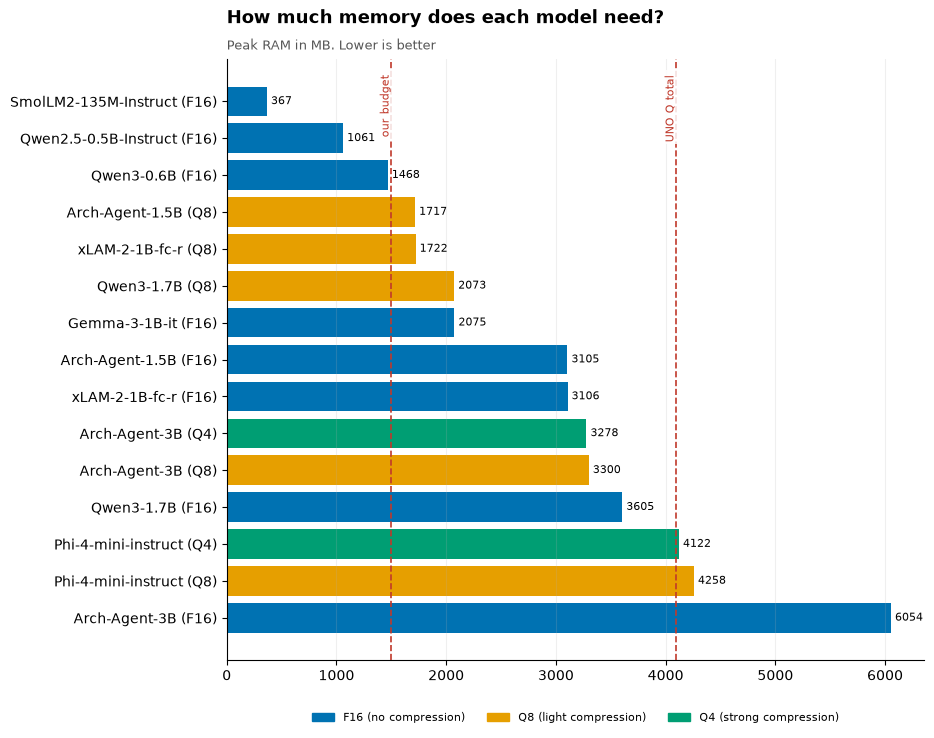

In [4]:
df = st.load("performance")
st.bar_chart(df, "ram_peak_mb", "How much memory does each model need?",
             "Peak RAM in MB. Lower is better", percent=False,
             lines=[(st.RAM_BUDGET_MB, "our budget"), (st.UNO_Q_RAM_MB, "UNO Q total")],
             lower_is_better=True, name="07_ram")

## Biểu đồ 2 - Model nào trả lời kịp trong 2 giây?

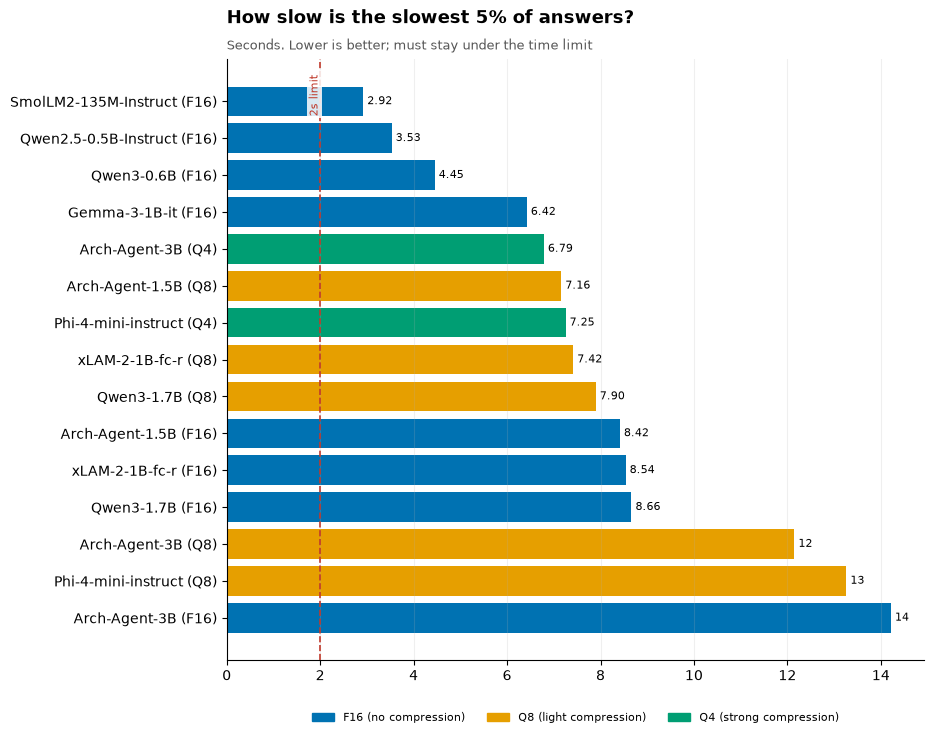

In [5]:
st.bar_chart(df, "total_p95_s", "How slow is the slowest 5% of answers?",
             "Seconds. Lower is better; must stay under the time limit", percent=False,
             lines=[(st.TTL_S, "2s limit")], lower_is_better=True, name="07_p95")

## Biểu đồ 3 - Độ ổn định của thời gian trả lời

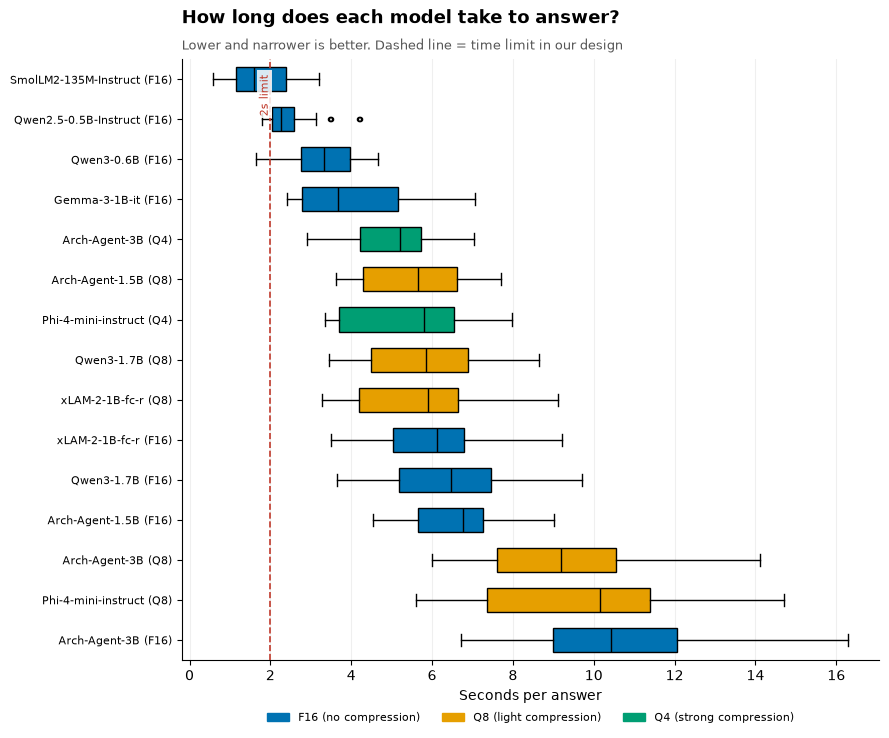

In [6]:
st.latency_boxplot(df)

## Biểu đồ 4 - Thêm công cụ làm model chậm đi bao nhiêu?

In [ ]:
st.grouped_bars(df, {"first_token_3_s": "3 tools", "first_token_11_s": "11 tools", "first_token_11_warm_s": "11 tools, cached prompt"},
                "Time until the first word appears", "Seconds. Lower is better. More tools = longer prompt = slower start",
                percent=False, lower_is_better=True, name="07_first_token")

In [8]:
only = [c for c in st.all_configs() if c["quant"] == "Q4_K_M"]
st.run_all("performance", measure, configs=only, threads=THREADS, gpu_layers=0, force=True)

[đang chạy] Arch-Agent-3B (Q4)
   xong sau 275s
[đang chạy] Phi-4-mini-instruct (Q4)
   xong sau 296s


In [9]:
import json
r = json.load(open("results/performance.json", encoding="utf-8"))
print({k: v["error"][:600] for k, v in r.items() if "error" in v})

{}


In [10]:
st.load("performance").query("quant == 'Q4_K_M'")[["label", "ram_peak_mb", "file_mb", "total_p95_s"]]

,label,ram_peak_mb,file_mb,total_p95_s
13,Arch-Agent-3B (Q4),2016.3,1840,8.942911
14,Phi-4-mini-instruct (Q4),2728.4,2378,11.196336


In [11]:
import functools
perf = st.load("performance")[["label", "ram_peak_mb", "file_mb", "total_p95_s"]]
parts = [perf,
         st.load("tool_calling")[["label", "acc_all"]].rename(columns={"acc_all": "tool"}),
         st.load("bfcl")[["label", "overall"]].rename(columns={"overall": "bfcl"}),
         st.load("faithfulness")[["label", "overall"]].rename(columns={"overall": "faith"})]
t = functools.reduce(lambda a, b: a.merge(b, on="label", how="outer"), parts)
t.round(2).sort_values("ram_peak_mb")

,label,ram_peak_mb,file_mb,total_p95_s,tool,bfcl,faith
12,SmolLM2-135M-Instruct (F16),366.8,258,2.92,0.15,0.00,0.10
8,Qwen2.5-0.5B-Instruct (F16),1061.4,948,3.53,0.25,0.48,0.53
9,Qwen3-0.6B (F16),1468.5,1439,4.45,0.20,0.63,0.80
1,Arch-Agent-1.5B (Q8),1717.2,1570,7.16,0.68,0.78,0.72
14,xLAM-2-1B-fc-r (Q8),1722.2,1570,7.42,0.53,0.70,0.72
3,Arch-Agent-3B (Q4),2016.3,1840,8.94,0.44,0.66,0.80
11,Qwen3-1.7B (Q8),2073.1,2065,7.90,0.16,0.81,0.75
5,Gemma-3-1B-it (F16),2075.4,1914,6.42,0.12,0.18,0.78
6,Phi-4-mini-instruct (Q4),2728.4,2378,11.20,0.15,0.83,0.87
0,Arch-Agent-1.5B (F16),3105.0,2950,8.42,0.68,0.77,0.72


In [12]:
st.load("tool_calling")[["label", "acc_3", "acc_6", "acc_11", "acc_clean", "acc_noisy", "over_trigger", "valid_json"]].round(2)

,label,acc_3,acc_6,acc_11,acc_clean,acc_noisy,over_trigger,valid_json
0,SmolLM2-135M-Instruct (F16),0.40,0.40,0.40,0.15,0.15,0.00,1.00
1,Qwen2.5-0.5B-Instruct (F16),0.25,0.08,0.18,0.27,0.23,1.00,1.00
2,Qwen3-0.6B (F16),0.63,0.62,0.52,0.23,0.17,0.00,1.00
3,Gemma-3-1B-it (F16),0.38,0.40,0.25,0.14,0.10,0.38,1.00
4,Arch-Agent-1.5B (F16),0.57,0.23,0.30,0.68,0.68,0.92,1.00
5,xLAM-2-1B-fc-r (F16),0.45,0.27,0.55,0.54,0.45,0.04,1.00
6,Qwen3-1.7B (F16),0.60,0.42,0.40,0.15,0.15,0.00,1.00
7,Arch-Agent-3B (F16),0.77,0.72,0.68,0.49,0.44,0.12,1.00
8,Arch-Agent-1.5B (Q8),0.57,0.23,0.28,0.69,0.67,0.96,1.00
9,xLAM-2-1B-fc-r (Q8),0.45,0.23,0.62,0.60,0.46,0.00,0.99


In [13]:
st.load("performance")[["label", "first_token_3_s", "first_token_11_s", "tokens_per_s", "total_p95_s"]].round(2)

,label,first_token_3_s,first_token_11_s,tokens_per_s,total_p95_s
0,SmolLM2-135M-Instruct (F16),0.33,0.92,107.22,2.92
1,Qwen2.5-0.5B-Instruct (F16),0.50,1.30,38.45,3.53
2,Qwen3-0.6B (F16),0.78,1.74,28.54,4.45
3,Gemma-3-1B-it (F16),1.18,3.08,19.48,6.42
4,Arch-Agent-1.5B (F16),1.58,3.51,14.20,8.42
5,xLAM-2-1B-fc-r (F16),1.44,3.25,14.74,8.54
6,Qwen3-1.7B (F16),1.56,3.51,12.91,8.66
7,Arch-Agent-3B (F16),2.73,6.07,7.88,14.22
8,Arch-Agent-1.5B (Q8),1.98,4.63,25.89,7.16
9,xLAM-2-1B-fc-r (Q8),2.07,4.60,24.65,7.42
